# Solubility tiers

[01_prep_and_analysis.ipynb](01_prep_and_analysis.ipynb) hands over one row per independent measurement — a *vote*, with copies already collapsed, gross errors flagged rather than deleted, and each compound's consensus alongside. It put a typical measurement's information at about 1.5–1.6 bits, 1.3–1.9 across its sensitivity grid: roughly three distinguishable solubility levels, between two and four depending on where copies end.

Rather than round that floor into a number of tiers, this notebook lets repeat measurements decide. The models will predict which of $K$ tiers a compound falls in, and a tier is only a meaningful label if a second measurement of the same compound mostly lands in the same tier. For each $K$ we find the boundaries that keep repeats together on half of the replicated compounds, score them on the other half, and read off two things: how many bits a second measurement shares with the first about the tier — the **repeat-measurement benchmark** every later model is compared with — and how often the two agree. The number of tiers is then a declared choice against that curve.

Two choices up front. Flagged votes take no part in the benchmark and get weight zero downstream: a value more than 1.5 logS from its own compound's consensus is, by construction, not a measurement of the same thing, so it should neither shape the tiers nor score a model. They stay in the file with their flag. And every compound counts once: a vote carries weight $1/n$, with $n$ its compound's number of unflagged votes, as throughout.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TARGET = "Solubility"  # LogS, mol/L

# One row per independent measurement (vote), written by 01_prep_and_analysis.ipynb: copies collapsed, gross
# errors flagged, each compound's consensus alongside.
votes = pd.read_csv(ROOT / "data" / "aqsoldb_measurements.csv")
good = votes[~votes["flagged"]].copy()
good["weight"] = 1 / good.groupby("InChIKey")[TARGET].transform("size")  # every compound counts once

by_compound = good.groupby("InChIKey")[TARGET].apply(np.array)
replicated = by_compound[by_compound.map(len) >= 2]
print(
    f"{len(votes)} votes for {votes['InChIKey'].nunique()} compounds; {int(votes['flagged'].sum())} flagged votes set aside\n"
    f"{len(replicated)} compounds have 2+ unflagged votes ({replicated.map(len).sum()} votes, up to {replicated.map(len).max()} each): "
    "the only compounds on which a second measurement can be compared with the first"
)

12097 votes for 9946 compounds; 84 flagged votes set aside
1580 compounds have 2+ unflagged votes (3647 votes, up to 13 each): the only compounds on which a second measurement can be compared with the first


## Mutual information between the tiers of two votes for one compound

Let $T_1$ and $T_2$ be the tiers that two votes for the same compound land in. Then

$$I(T_1;T_2) = \sum_{a,b} p(a,b)\,\log_2\frac{p(a,b)}{p(a)\,p(b)} \;\le\; H(T_1) \;\le\; \log_2 K$$

The first bound is reached when one vote's tier fixes the other's (nothing off the diagonal), the second when every tier holds an equal share. The toy joint distributions below, drawn for four tiers, show both. MI rewards any one-to-one pattern, not only the diagonal (last row); for ordered tiers and votes of one compound, the diagonal is the only one we expect.

In [2]:
def mutual_info(p: np.ndarray) -> float:
    """MI (bits) of a joint distribution."""
    p = p / p.sum()
    independent = p.sum(1, keepdims=True) * p.sum(0, keepdims=True)
    nz = p > 0
    return float((p[nz] * np.log2(p[nz] / independent[nz])).sum())


def entropy(q: np.ndarray) -> float:
    """Entropy (bits) of a distribution."""
    q = q[q > 0]
    return float(-(q * np.log2(q)).sum())


def neighbours(e: float) -> np.ndarray:
    """25% per tier, with a share e of all pairs in each cell next to the diagonal."""
    p = np.diag([0.25 - e, 0.25 - 2 * e, 0.25 - 2 * e, 0.25 - e])
    i = np.arange(3)
    p[i, i + 1] = p[i + 1, i] = e
    return p


toys = {
    "25% per tier, nothing off the diagonal": np.diag([0.25] * 4),
    "unequal tiers, nothing off the diagonal": np.diag([0.4, 0.3, 0.2, 0.1]),
    "90/5/4/1, nothing off the diagonal": np.diag([0.9, 0.05, 0.04, 0.01]),
    "25% per tier, some pairs in neighbouring tiers": neighbours(0.025),
    "25% per tier, more pairs in neighbouring tiers": neighbours(0.05),
    "25% per tier, tiers of the two votes unrelated": np.full((4, 4), 1 / 16),
    "25% per tier, swapped one-to-one (0↔1, 2↔3)": 0.25 * np.eye(4)[[1, 0, 3, 2]],
}
pd.DataFrame(
    {
        "tier shares (%)": ["/".join(f"{100 * s:g}" for s in p.sum(1)) for p in toys.values()],
        "% off the diagonal": [round(100 * (1 - np.trace(p))) for p in toys.values()],
        "H(T) (bits)": [round(entropy(p.sum(1)), 2) for p in toys.values()],
        "MI (bits)": [round(mutual_info(p), 2) for p in toys.values()],
    },
    index=toys.keys(),
)

,tier shares (%),% off the diagonal,H(T) (bits),MI (bits)
"25% per tier, nothing off the diagonal",25/25/25/25,0,2.00,2.00
"unequal tiers, nothing off the diagonal",40/30/20/10,0,1.85,1.85
"90/5/4/1, nothing off the diagonal",90/5/4/1,0,0.61,0.61
"25% per tier, some pairs in neighbouring tiers",25/25/25/25,15,2.00,1.30
"25% per tier, more pairs in neighbouring tiers",25/25/25/25,30,2.00,0.95
"25% per tier, tiers of the two votes unrelated",25/25/25/25,75,2.00,0.00
"25% per tier, swapped one-to-one (0↔1, 2↔3)",25/25/25/25,100,2.00,2.00


## Choosing the number of tiers on held-out repeats

Candidate boundaries sit every 0.1 logS across the range of votes. For a given $K$, boundaries are found by coordinate ascent from the $K$-quantiles of the votes: move one boundary at a time over every candidate between its neighbours, keep any move that raises $I(T_1;T_2)$ over the replicate pairs, and repeat until nothing moves. Pairs are counted in both orders, since their order is arbitrary, and each compound's pairs share one unit of weight so a compound with many votes cannot dominate.

Boundaries tuned on the same pairs they are scored on flatter themselves, so the score is cross-fitted: the replicated compounds are halved at random, boundaries are fitted on one half and scored on the other, both ways, over 20 random halvings. The table reports the held-out mutual information (mean, with its spread over halvings), the entropy of the tier itself, their ratio — the share of the tier's uncertainty that a second measurement removes — and how often the two votes land in the same tier. Quantile boundaries, with no tuning at all, are scored the same way as the reference.

The rule for $K$ is declared before reading the table, and it is our choice: a tier is a label only if a repeat measurement reproduces it at least three times in four, so $K$ is the largest number of tiers whose held-out same-tier rate stays at or above 75%. Information itself keeps rising with $K$ — finer tiers always carry more bits about each other — so this is a choice about label reliability, not about information, and the full curve is shown so that a different standard can be read off it.

In [3]:
STEP = 0.1  # logS between candidate boundaries
KS = [2, 3, 4, 5, 6, 8]
SPLITS = 20  # random halvings of the replicated compounds; our choice
MIN_SAME_TIER = 75  # our choice: a repeat must reproduce the tier at least three times in four

# Ordered replicate pairs (both orders), each compound's pairs sharing one unit of weight.
pairs = pd.DataFrame(
    [
        (c, a, b, 1 / (len(v) * (len(v) - 1)))
        for c, v in enumerate(replicated)
        for i, a in enumerate(v)
        for j, b in enumerate(v)
        if i != j
    ],
    columns=["compound", "y1", "y2", "w"],
)
candidates = np.round(np.arange(np.floor(good[TARGET].min()), good[TARGET].max() + STEP, STEP), 1)
G = len(candidates) - 1
fine1, fine2 = np.digitize(pairs["y1"], candidates), np.digitize(pairs["y2"], candidates)  # fine bins 0..G+1
compound, w = pairs["compound"].to_numpy(), pairs["w"].to_numpy()


def cumulative(mask: np.ndarray) -> np.ndarray:
    """cum[i+1, j+1] = weight of pairs with fine bins (<= i, <= j); a zero row and column in front make block sums easy."""
    c = np.zeros((G + 3, G + 3))
    np.add.at(c, (fine1[mask] + 1, fine2[mask] + 1), w[mask])
    return c.cumsum(0).cumsum(1)


def joint(cum: np.ndarray, cuts: list[int]) -> np.ndarray:
    """Joint distribution of (tier of y1, tier of y2) for cut indices into `candidates`: cut c puts the boundary at candidates[c-1]."""
    e = np.array([0, *cuts, G + 2])
    big = cum[np.ix_(e, e)]
    p = big[1:, 1:] - big[:-1, 1:] - big[1:, :-1] + big[:-1, :-1]
    p = np.where(p > 1e-12, p, 0)  # round-off left by the subtraction
    return p / p.sum()


def quantile_cuts(k: int) -> list[int]:
    """Boundaries at the k-quantiles of all unflagged votes, each compound weighted once: the no-tuning reference."""
    order = np.argsort(good[TARGET].to_numpy())
    values, cdf = good[TARGET].to_numpy()[order], np.cumsum(good["weight"].to_numpy()[order]) / good["weight"].sum()
    return [int(np.clip(np.searchsorted(candidates, values[np.searchsorted(cdf, q)]), 1, G + 1)) for q in np.arange(1, k) / k]


def optimize(cum: np.ndarray, k: int, start: list[int]) -> tuple[list[int], float]:
    """Coordinate ascent: move one boundary at a time over every candidate between its neighbours until MI stops rising."""
    cuts, best = list(start), mutual_info(joint(cum, start))
    improved = True
    while improved:
        improved = False
        for j in range(k - 1):
            lo = cuts[j - 1] + 1 if j else 1
            hi = cuts[j + 1] - 1 if j < k - 2 else G + 1
            for c in range(lo, hi + 1):
                trial = [*cuts[:j], c, *cuts[j + 1:]]
                value = mutual_info(joint(cum, trial))
                if value > best + 1e-12:
                    cuts, best, improved = trial, value, True
    return cuts, best


rng = np.random.default_rng(0)
n_compounds = len(replicated)
held_out, rows = {}, []
for k in KS:
    start, scores = quantile_cuts(k), []
    for _ in range(SPLITS):
        perm = rng.permutation(n_compounds)
        halves = [np.isin(compound, perm[: n_compounds // 2]), np.isin(compound, perm[n_compounds // 2 :])]
        for fit, test in [(halves[0], halves[1]), (halves[1], halves[0])]:
            cuts, _ = optimize(cumulative(fit), k, start)
            p, cum_test = joint(cumulative(test), cuts), cumulative(test)
            scores.append({"MI": mutual_info(p), "H": entropy(p.sum(1)), "same": np.trace(p), "MI quantile": mutual_info(joint(cum_test, start))})
    held_out[k] = pd.DataFrame(scores)
    s = held_out[k]
    rows.append(
        {
            "tiers K": k,
            "held-out MI, tuned boundaries (bits)": s["MI"].mean(),
            "spread over halvings": s["MI"].std(),
            "held-out MI, quantile boundaries (bits)": s["MI quantile"].mean(),
            "tier entropy H(T) (bits)": s["H"].mean(),
            "MI / H(T)": s["MI"].mean() / s["H"].mean(),
            "same tier (%)": 100 * s["same"].mean(),
        }
    )
curve = pd.DataFrame(rows).set_index("tiers K")
curve["gain per added tier (bits)"] = curve["held-out MI, tuned boundaries (bits)"].diff() / curve.index.to_series().diff()
K = int(curve.index[curve["same tier (%)"] >= MIN_SAME_TIER].max())
print(f"largest K with a held-out same-tier rate of at least {MIN_SAME_TIER}%: K = {K}")
curve.round(3)

largest K with a held-out same-tier rate of at least 75%: K = 4


,"held-out MI, tuned boundaries (bits)",spread over halvings,"held-out MI, quantile boundaries (bits)",tier entropy H(T) (bits),MI / H(T),same tier (%),gain per added tier (bits)
tiers K,,,,,,,
2,0.525,0.030,0.513,0.992,0.529,90.015,NaN
3,0.748,0.026,0.751,1.534,0.487,82.147,0.223
4,0.963,0.040,0.937,1.981,0.486,76.548,0.215
5,1.070,0.041,1.068,2.294,0.467,70.660,0.108
6,1.134,0.037,1.136,2.533,0.448,65.808,0.064
8,1.221,0.040,1.247,2.932,0.416,56.835,0.044


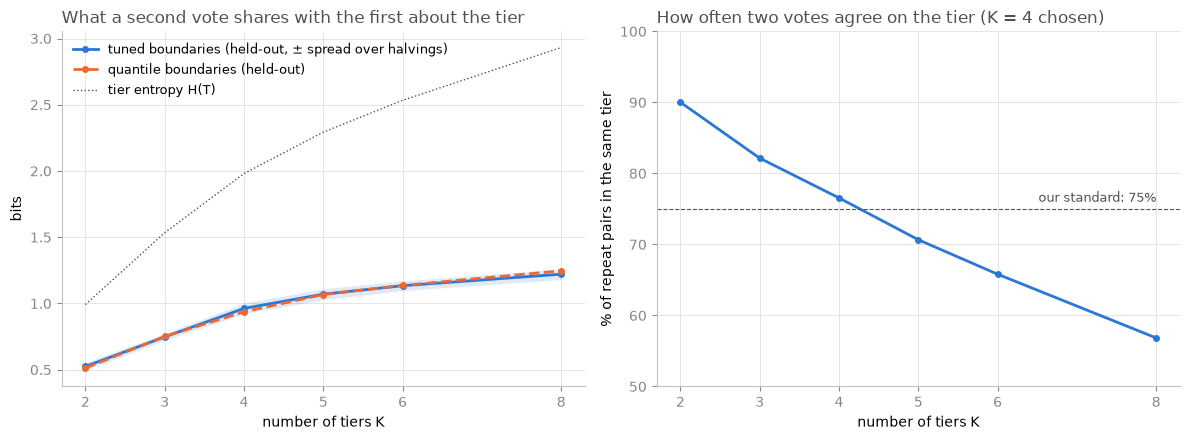

In [4]:
import matplotlib.pyplot as plt

INK, MUTED, GRID, AXIS = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"  # as in 01_prep_and_analysis.ipynb
SERIES = ["#2a78d6", "#eb6834"]


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.tick_params(colors=MUTED)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.set(xticks=KS, xlabel="number of tiers K")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
mi, sd = curve["held-out MI, tuned boundaries (bits)"], curve["spread over halvings"]
axes[0].fill_between(KS, mi - sd, mi + sd, color=SERIES[0], alpha=0.15, lw=0)
axes[0].plot(KS, mi, color=SERIES[0], lw=2, marker="o", ms=4, label="tuned boundaries (held-out, ± spread over halvings)")
axes[0].plot(KS, curve["held-out MI, quantile boundaries (bits)"], color=SERIES[1], lw=2, ls="--", marker="o", ms=4, label="quantile boundaries (held-out)")
axes[0].plot(KS, curve["tier entropy H(T) (bits)"], color=INK, lw=1, ls=":", label="tier entropy H(T)")
axes[0].set(ylabel="bits")
axes[0].set_title("What a second vote shares with the first about the tier", loc="left", color=INK)
axes[0].legend(frameon=False, fontsize=9, loc="upper left")
axes[1].plot(KS, curve["same tier (%)"], color=SERIES[0], lw=2, marker="o", ms=4)
axes[1].axhline(MIN_SAME_TIER, color=INK, ls="--", lw=0.8)
axes[1].text(KS[-1], MIN_SAME_TIER + 1, f"our standard: {MIN_SAME_TIER}%", ha="right", color=INK, fontsize=9)
axes[1].set(ylabel="% of repeat pairs in the same tier", ylim=(50, 100))
axes[1].set_title(f"How often two votes agree on the tier (K = {K} chosen)", loc="left", color=INK)
for ax in axes:
    style(ax)
fig.tight_layout()

Information rises with $K$ and does not stop: about half a bit at two tiers, close to one bit at four, over 1.2 bits at eight. But each added tier returns less than the one before, and the two votes agree less often — nine times in ten at two tiers, about three in four at four, not much better than one in two at eight. Tuning the boundaries buys almost nothing over plain quantiles: a few hundredths of a bit at $K = 4$, inside the spread over halvings, and nothing at all from $K = 5$ up. The data say little about exactly where the boundaries sit, which is worth remembering whenever a boundary looks meaningful later.

The 75% standard picks **four tiers**: a repeat reproduces the tier about 76% of the time there and about 71% at five. Four tiers is also where the tier's own entropy, 2 bits, sits just above the 1.3–1.9 bits a single measurement carries: the tiers are slightly finer than one measurement resolves, which is exactly why a quarter of repeats disagree on the tier.

The benchmark is read from the held-out scores, not from boundaries refitted on everything: about **0.96 bits**, with the two votes in the **same tier about 76%** of the time. A model whose predicted tier agreed with the measured tier this well would be as good as measuring the compound again. Two cautions for the later notebooks. The tier's entropy is not a reachable ceiling for any model, because the measured tier is itself noisy. And the repeat benchmark is not the ceiling either: a second measurement is a noisy witness, so a perfect model of a compound's true solubility could in principle share *more* with a measured tier than another measurement does (the data-processing inequality runs that way). The reachable ceiling lies somewhere between the two.

In [5]:
# Boundaries for the chosen K, fitted on every replicated compound; the benchmark stays the held-out one above.
everything = np.ones(len(pairs), bool)
cuts, mi_in_sample = optimize(cumulative(everything), K, quantile_cuts(K))
CUTS = candidates[np.array(cuts) - 1]
p = joint(cumulative(everything), cuts)
benchmark = held_out[K]
print(
    f"{K} tiers, boundaries at {', '.join(f'{c:.1f}' for c in CUTS)} logS (fitted on all {n_compounds} replicated compounds)\n"
    f"repeat-measurement benchmark, held-out: {benchmark['MI'].mean():.3f} ± {benchmark['MI'].std():.3f} bits, "
    f"{100 * benchmark['same'].mean():.1f}% in the same tier; "
    f"in-sample at these boundaries: {mi_in_sample:.3f} bits, {100 * np.trace(p):.1f}%"
)

labels = [f"tier {t}" for t in range(K)]
display((100 * pd.DataFrame(p, index=labels, columns=labels)).round(1).rename_axis(index="one vote", columns="other vote"))

# Given one vote's tier, where does another vote of the same compound land? Each row sums to 100%.
apart = np.abs(np.subtract.outer(range(K), range(K)))
groups = {"same tier": apart == 0, "1 tier away": apart == 1, "2+ tiers away": apart >= 2}
by_tier = pd.DataFrame({name: (p * m).sum(1) / p.sum(1) for name, m in groups.items()}, index=labels)
by_tier.loc["all pairs"] = [p[m].sum() for m in groups.values()]
(100 * by_tier).round(1).rename_axis("one vote's tier")

4 tiers, boundaries at -5.3, -3.3, -1.5 logS (fitted on all 1580 replicated compounds)
repeat-measurement benchmark, held-out: 0.963 ± 0.040 bits, 76.5% in the same tier; in-sample at these boundaries: 1.008 bits, 77.9%


other vote,tier 0,tier 1,tier 2,tier 3
one vote,,,,
tier 0,17.2,2.8,0.4,0.1
tier 1,2.8,18.2,3.7,0.4
tier 2,0.4,3.7,20.2,3.7
tier 3,0.1,0.4,3.7,22.3


,same tier,1 tier away,2+ tiers away
one vote's tier,,,
tier 0,83.9,13.6,2.5
tier 1,72.6,25.7,1.7
tier 2,72.4,26.2,1.3
tier 3,84.1,13.8,2.2
all pairs,77.9,20.2,1.9


## Tiers and bit vectors per vote

One row per vote, so a compound whose votes fall in different tiers carries more than one tier: the labels keep the disagreement the floor was estimated with. Bit vectors use a reflected Gray code (00, 01, 11, 10): the joint distribution above puts most disagreements one tier apart and very few two or more, so neighbouring tiers should differ in one bit. Each vote also carries the tier of its compound's consensus, for analyses that want a single label per compound. Weights are $1/n$ over a compound's unflagged votes, and 0 for flagged votes.

Next, [03_splits.ipynb](03_splits.ipynb) divides the compounds into train, validation and test sets, so that models can be scored on compounds they have not seen.

In [6]:
BITS = int(np.ceil(np.log2(K)))
GRAY = np.array([[(i ^ (i >> 1)) >> b & 1 for b in reversed(range(BITS))] for i in range(K)])  # reflected Gray code
assert (np.abs(np.diff(GRAY, axis=0)).sum(axis=1) == 1).all(), "neighbouring tiers must differ in one bit"

votes["tier"] = np.digitize(votes[TARGET], CUTS)
votes["consensus_tier"] = np.digitize(votes["consensus"], CUTS)
for b in range(BITS):
    votes[f"bit_{b + 1}"] = GRAY[votes["tier"], b]
unflagged_per_compound = votes.groupby("InChIKey")["flagged"].transform(lambda f: (~f).sum())
votes["weight"] = np.where(votes["flagged"], 0.0, 1 / unflagged_per_compound)
assert np.isclose(votes["weight"].sum(), votes["InChIKey"].nunique()), "each compound should total weight 1"

votes.to_csv(ROOT / "data" / "aqsoldb_tiers.csv", index=False)
print(
    f"{len(votes)} rows, {votes['InChIKey'].nunique()} compounds; "
    f"{(votes[~votes['flagged']].groupby('InChIKey')['tier'].nunique() > 1).sum()} compounds carry more than one tier "
    f"among their unflagged votes -> data/aqsoldb_tiers.csv"
)
pd.DataFrame(
    {
        "logS from": [votes[TARGET].min(), *CUTS],
        "logS to": [*CUTS, votes[TARGET].max()],
        "bit vector": ["".join(map(str, b)) for b in GRAY],
        "votes": votes["tier"].value_counts().sort_index(),
        "% of compounds (weighted)": 100 * votes.groupby("tier")["weight"].sum() / votes["weight"].sum(),
    }
).round(2).rename_axis("tier")

12097 rows, 9946 compounds; 397 compounds carry more than one tier among their unflagged votes -> data/aqsoldb_tiers.csv


,logS from,logS to,bit vector,votes,% of compounds (weighted)
tier,,,,,
0,-13.17,-5.30,00,2077,15.89
1,-5.30,-3.30,01,2780,22.36
2,-3.30,-1.50,11,3722,31.81
3,-1.50,2.14,10,3518,29.93
